<a href="https://colab.research.google.com/github/Tiyinolalekan/Deep_Learning_Image_Classifier/blob/main/First_Stage_Classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ***First Stage: Router***
___________________
Determines whether an item is a book, clothing item or food item.

In [35]:
#Imports
import torch #Main PyTorch library
import torch.nn as nn # Neural network compnents
import torch.optim as optim #Optimisers for training
import torchvision #Computer-vision datasets/tools
from torchvision import datasets, models #Importing datasets and models
import torchvision.transforms as transforms #Preparing images
import matplotlib.pyplot as plt #to visualise images
from torch.utils.data import DataLoader
from torchvision.utils import make_grid
import time
import copy
import numpy as np
import pandas as pd

#CHECKING IMPORTS AND STUFF
print(torch.__version__)
print(torch.cuda.is_available()) #Checking if a GPU is available

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu') ##Resulting to use CPU if GPU isnt available. GPU is preferred cause it performs multiple AI mathematical calculations faster
print(device)



2.11.0+cpu
False
cpu


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Trasnforming data using the torchvision.transforms library

In [1]:
import os
print(os.getcwd())

/content


In [13]:
from pathlib import Path

print(Path("drive/MyDrive/neura_data/router_dataset/train").exists()) #checking if file exists
#print(Path("neura_data/router_dataset/val").exists())

root_path = "drive/MyDrive/neura_data/router_dataset"
train_dir = root_path + "/train"
val_dir = root_path + "/val"
test_dir = root_path + "/test"

True


**Normalisation using empirically determined mean and standard deviation values.**

In [40]:
mean = [0.485, 0.456, 0.406] #Imperatively found as studies show
std = [0.229, 0.224, 0.225]

**De-normalise the images**

In [39]:
inv_normalize = transforms.Normalize(
    mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
    std=[1/0.229, 1/0.224, 1/0.225]
)

**Transformations**: Transforming the data using the torchvision library.

In [41]:
transform = transforms.Compose([
    transforms.Resize((96, 96)),  #Resezies to 96x96 pixels
    transforms.RandomHorizontalFlip(), #Default 0.5 i.e., 50% chance of image being flipped
    #transforms.RandomRotation(1,30), #Rtotating random inages from one to 30 degrees
    transforms.ToTensor(),  #Converting it to tensors
    transforms.Normalize(mean, std) #Normalising the images (will need to denormalise to view images properly)
])

#Copy of dataset for examples/checks below
train_dataset = datasets.ImageFolder(
    train_dir,
    transform=transform
)

Peeking at class structure

In [15]:
print(train_dataset.classes)

['book', 'clothes', 'grocery']


In [16]:
#Naming Classes
classes = ['book', 'clothes', 'grocery']

#Peeking
image, label = train_dataset[0]
print(image.shape) #First element represents the number of color channels,a nd remaning two is the height and width based on the number of pixels
print(label)
print(classes[label])

torch.Size([3, 96, 96])
0
book


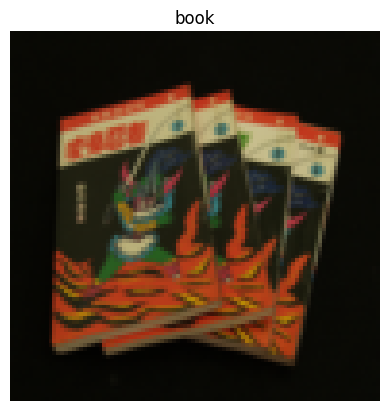

In [17]:
#Displaying image using matplotlib

plt.imshow(image.permute(1,2,0)) #rearranged dimensions to be height, width and channels where, 0,1,2 are indicies from the image.shape array e.g., [3,32,32] becomes (32,32,3)
plt.title(classes[label])
plt.axis("off")
plt.show()

**CREATING THE MODEL**

In [55]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  #Using the CPU to train if no GPU's are detected

class CNN(nn.Module): #Inheritnce class
    def __init__(self):
        super().__init__() #Ingeriting attributes from parent class

        #First Block
        self.block1 = nn.Sequential(
               nn.Conv2d(
                        in_channels=3,
                        out_channels=16,
                        kernel_size=3,
                        padding=1
                    ),

                nn.BatchNorm2d(16),
                nn.ReLU(),
                nn.MaxPool2d(2) # where kernel_size=2 stride=2
        )



        #Second Convolutional layer
        self.block2 = nn.Sequential(
                     nn.Conv2d(
                              in_channels=16,
                              out_channels=32,
                              kernel_size=3,
                              padding=1
                          ),

                      nn.BatchNorm2d(32),
                      nn.ReLU(),
                      nn.MaxPool2d(2) # where kernel_size=2 stride=2
              )

        #Third Convolutional layer
        self.block3 = nn.Sequential(
                    nn.Conv2d(
                        in_channels=32,
                        out_channels=64,
                        kernel_size=3,
                        padding=1
                        ),

                    nn.BatchNorm2d(64),
                    nn.ReLU(),
                #Do two times the convolution in the third block
                  nn.Conv2d(
                          in_channels=64,
                          out_channels=64,
                          kernel_size=3,
                          padding=1
                        ),

                    nn.BatchNorm2d(64),
                    nn.ReLU(),
                    nn.MaxPool2d(2) # where kernel_size=2 stride=2
            )

        #Fourth Convolutional layer
        self.block4 = nn.Sequential(
                            nn.Conv2d(
                                    in_channels=64,
                                    out_channels=128,
                                    kernel_size=3,
                                    padding=1
                                ),

                            nn.BatchNorm2d(128),
                            nn.ReLU(),
                        #Do two times the convolution in the third block according to VGG
                            nn.Conv2d(
                                in_channels=128,
                                out_channels=128,
                                kernel_size=3,
                                padding=1
                               ),

                            nn.BatchNorm2d(128),
                            nn.ReLU(),
                            nn.MaxPool2d(2) # where kernel_size=2 stride=2
                    )

    def forward():
        #Using the blocks assemebeled and applying them sequentially to the variable
        x= self.block1(x)
        x= self.block2(x)
        x= self.block3(x)
        x= self.block4(x)


        x= torch.flatten(x, 1)  #Flattening the one dimention
        x = self.dropout(x)  #Randomly deactivating neuraons by zeroing out a fraction of neurons in a layer to provent overfittig
        x = self.fc(x) #Fully connected layer

        return x



In [56]:
 #Instantiate and move to device
model = CNN()
model = model.to(device) #Moving to GPU if avilable

Loading the data into the model

In [57]:
#Getting test data from their folders
train_dataset = datasets.ImageFolder(
    train_dir,
    transform=transform
)

val_dataset = datasets.ImageFolder(
    val_dir,
    transform=transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=transform
)
#torch.manual_seed(42) #Seeding the dataset to get the same results all the time
#Loading the data in batches of 64 then shuffling it to enable randomisation and efficient learning
train_loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True
)

test_loader = DataLoader(
    test_dataset, batch_size=64, shuffle=True
)

val_loader = DataLoader(
    val_dataset, batch_size=64, shuffle=False
)

#Loss Function
criterion = nn.CrossEntropyLoss()

#Optimizer
optimizer = optim.Adam( #the algorithm we're using to update the weights
    model.parameters(),#all the weights and biases the model can learn
    lr=0.001 #learning rate, controlling how big each weight update is
)

Peeking into the dataset.

In [22]:
train_dataset

Dataset ImageFolder
    Number of datapoints: 9035
    Root location: drive/MyDrive/neura_data/router_dataset/train
    StandardTransform
Transform: Compose(
               Resize(size=(96, 96), interpolation=bilinear, max_size=None, antialias=True)
               ToTensor()
           )

In [29]:
len(train_dataset)

9035

In [27]:
len(test_dataset)


1125

In [28]:
len(val_dataset)

1085

Displaying image Batch

Lables:  [1 0 1 1 1 0 1 1 0 0 2 2 2 1 1 1 0 2 2 2 0 2 2 1 1 0 1 2 1 1 2 2 2 2 2 0 2
 0 0 0 2 0 2 1 2 1 1 2 1 1 0 1 0 0 1 0 0 2 1 2 2 2 2 1]
Classes:  clothes book clothes clothes clothes book clothes clothes book book grocery grocery grocery clothes clothes clothes book grocery grocery grocery book grocery grocery clothes clothes book clothes grocery clothes clothes grocery grocery grocery grocery grocery book grocery book book book grocery book grocery clothes grocery clothes clothes grocery clothes clothes book clothes book book clothes book book grocery clothes grocery grocery grocery grocery clothes


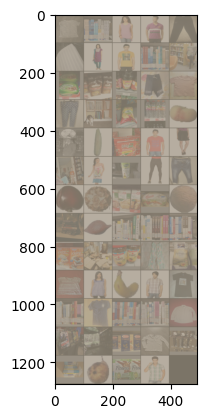

In [42]:
for images, labels in train_loader:
  break #we just want the labels

print('Lables: ', labels.numpy())
print("Classes: ", *np.array([classes[i] for i in labels]))

im = make_grid(images, nrow=5)
im_inv = inv_normalize(im) #De normalising images
plt.imshow(np.transpose(im_inv.numpy(), (1,2,0)))
plt.show()

Training Loop

In [58]:
num_epochs = 10 #the model goes through the entire 50,000-image training dataset 10 times.
train_losses = []

for epoch in range(num_epochs) :

  model.train() #Training the model
  running_loss = 0.0

  for images, labels in train_loader: #Iterating through the 64/50,000-image training dataset

    images = images.to(device) #moving images to GPU if available
    lables = labels.to(device)

    optimizer.zero_grad() #clears the gradients from the previous batch

    outputs = model(images) #forward pass; the CNN makes predictions.

    #outputs are raw logits; CrossEntropyLoss handles softmax internally

    loss = criterion(outputs, labels) # calculates how wrong those predictions are.

    loss.backward() #backpropagation; calculates the gradient for EVERY learnable weight.

    optimizer.step() #uses those gradients to update the weights.

    running_loss += loss.item()

  epoch_loss = running_loss/len(train_loader)
  train_losses.append(epoch_loss)
  print(
        f"Epoch {epoch+1}/{num_epochs},"
        f"Loss: {epoch_loss:.4f}"
    )

KeyboardInterrupt: 